# 🚗 Car Price Prediction

### Oasis Infobyte Data Science Internship — Task 3

**Objective:** Predict the selling price of a used car using machine learning regression models.

**Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**Models:** Linear Regression, Decision Tree Regressor, Random Forest Regressor

In [5]:
from google.colab import files

uploaded = files.upload()

Saving car data.csv to car data (1).csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("car data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing values:


,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0



Duplicate rows: 2

Statistical summary:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


## 3. Exploratory Data Analysis (EDA)

In this section, we explore the car dataset to understand selling prices, present prices, manufacturing years, fuel types, transmission types, and other factors that influence used car prices.

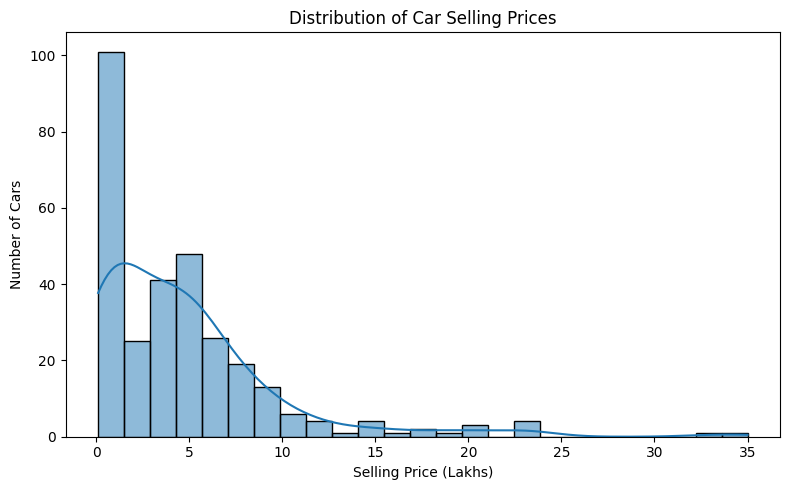

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Selling_Price", kde=True, bins=25)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

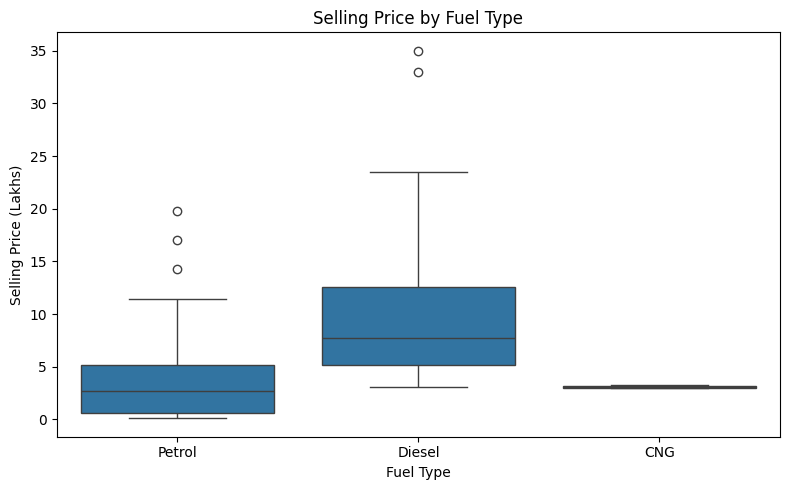

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

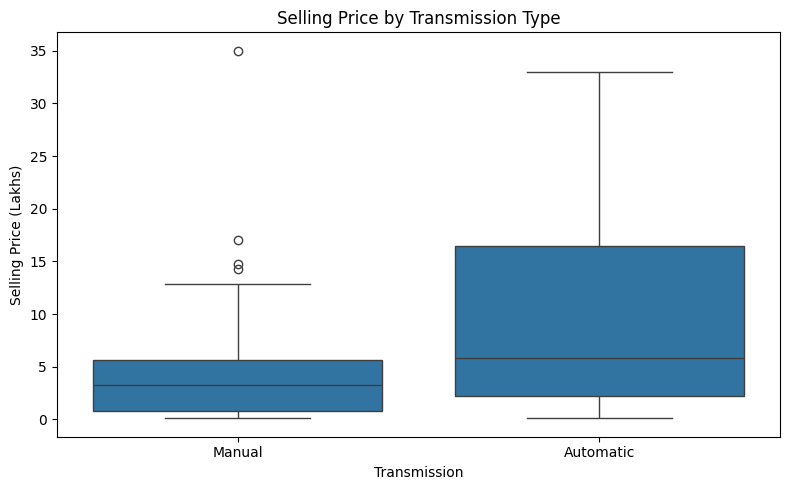

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Transmission", y="Selling_Price")
plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

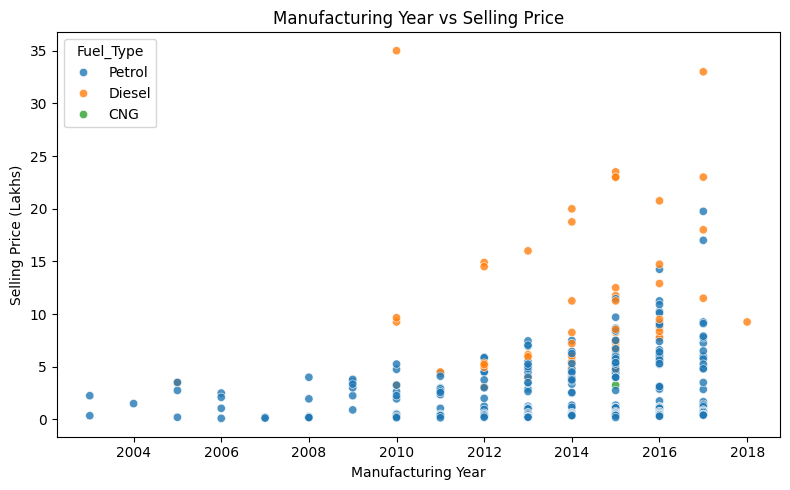

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Year",
    y="Selling_Price",
    hue="Fuel_Type",
    alpha=0.8
)
plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

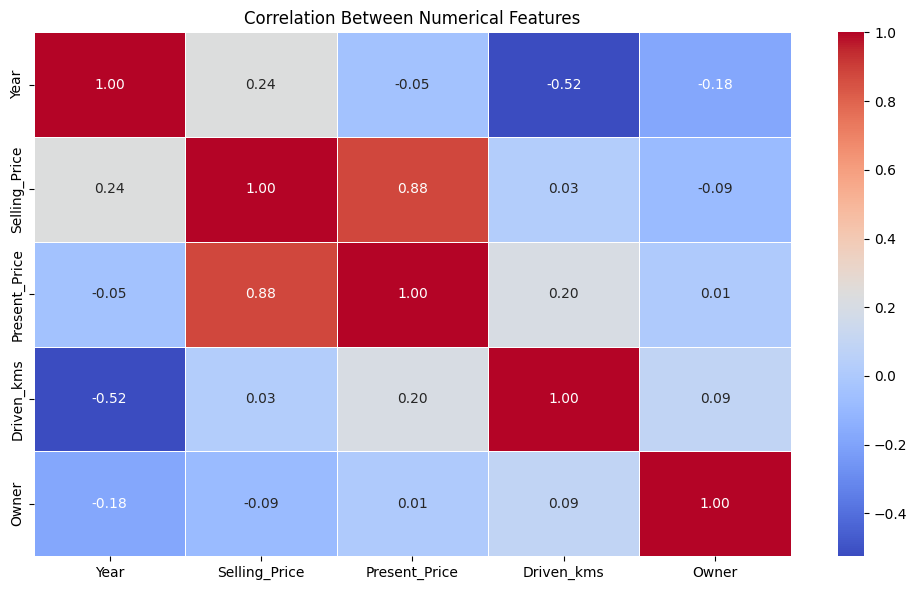

In [11]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing and Feature Engineering

In this step, categorical variables are converted into numerical values, relevant input features are selected, and the dataset is split into training and testing sets for model development and evaluation.

In [12]:
# Create a copy so the original dataset remains unchanged
model_df = df.copy()

# Remove the car name because it is a high-cardinality identifier
model_df = model_df.drop(columns=["Car_Name"])

# Convert categorical columns into numerical dummy variables
model_df = pd.get_dummies(
    model_df,
    columns=["Fuel_Type", "Selling_type", "Transmission"],
    drop_first=True,
    dtype=int
)

# Separate input features and target
X = model_df.drop(columns=["Selling_Price"])
y = model_df["Selling_Price"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(X.columns.tolist())

display(X.head())

Feature shape: (301, 8)
Target shape: (301,)

Features used:
['Year', 'Present_Price', 'Driven_kms', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Selling_type_Individual', 'Transmission_Manual']


,Year,Present_Price,Driven_kms,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,2014,5.59,27000,0,0,1,0,1
1,2013,9.54,43000,0,1,0,0,1
2,2017,9.85,6900,0,0,1,0,1
3,2011,4.15,5200,0,0,1,0,1
4,2014,6.87,42450,0,1,0,0,1


### Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The training set is used to fit the models, while the testing set is reserved for evaluating their performance on unseen records.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 240
Testing samples: 61
Number of input features: 8


## 5. Model Training

Three regression algorithms are trained to predict used car selling prices:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

The models are compared using MAE, RMSE, and R² score on the test dataset.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    trained_models[name] = model

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.6070,0.9275,0.9627
1,Decision Tree,0.7375,1.1337,0.9442
2,Linear Regression,1.2164,1.8658,0.8489


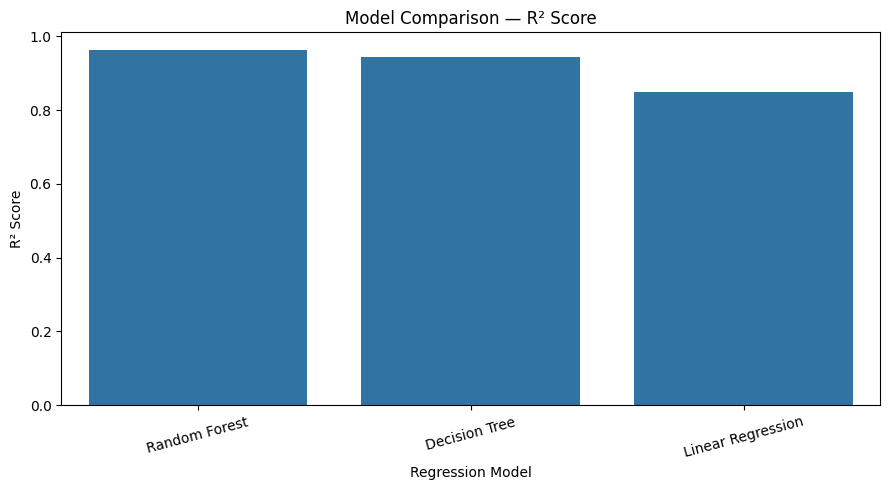

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison — R² Score")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Model Evaluation and Prediction Analysis

The best-performing model is selected based on the test R² score. Its predictions are compared with actual selling prices to understand model performance and prediction errors.

Best Model: Random Forest
MAE: 0.607
RMSE: 0.9275
R² Score: 0.9627


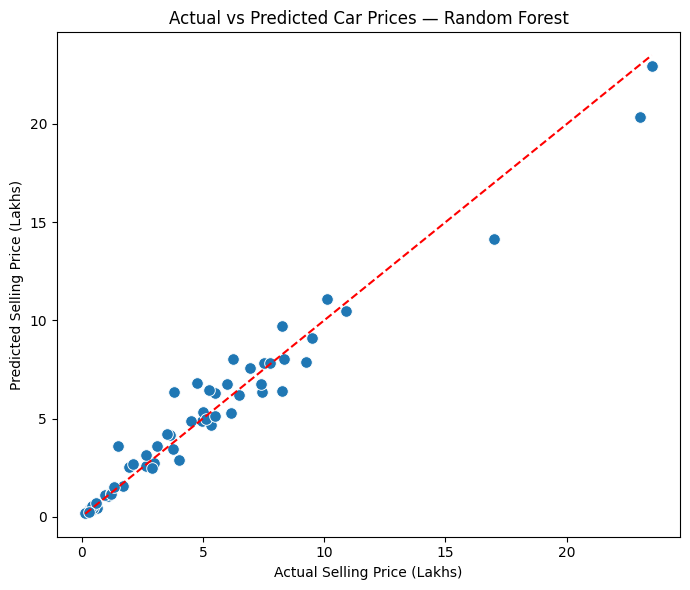

In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R² Score:", round(r2_score(y_test, y_pred), 4))

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, s=70)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.title(f"Actual vs Predicted Car Prices — {best_model_name}")
plt.xlabel("Actual Selling Price (Lakhs)")
plt.ylabel("Predicted Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

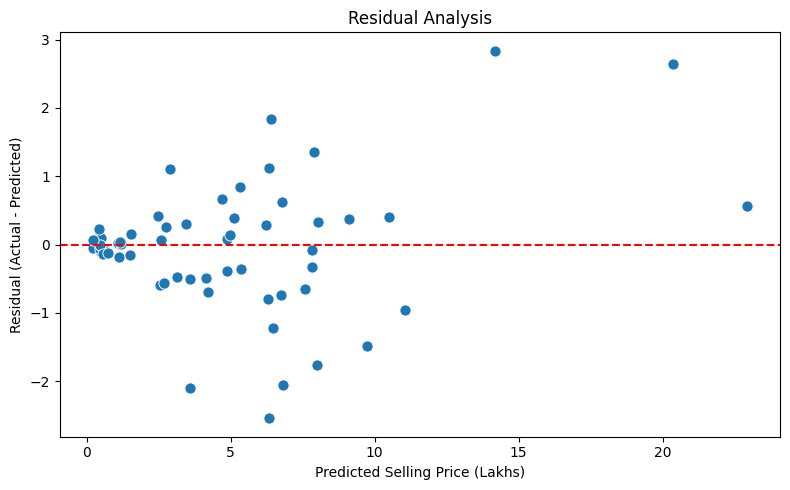

In [17]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, s=65)
plt.axhline(0, color="red", linestyle="--")

plt.title("Residual Analysis")
plt.xlabel("Predicted Selling Price (Lakhs)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

In [18]:
sample_car = pd.DataFrame([{
    "Year": 2018,
    "Present_Price": 8.0,
    "Kms_Driven": 30000,
    "Owner": 0,
    "Fuel_Type_Diesel": 1,
    "Fuel_Type_Petrol": 0,
    "Selling_type_Individual": 1,
    "Transmission_Manual": 1
}])

# Match the training feature order
sample_car = sample_car.reindex(columns=X.columns, fill_value=0)

predicted_price = best_model.predict(sample_car)[0]

print("Selected Model:", best_model_name)
print("Sample Car Details:")
display(sample_car)
print(f"Predicted Selling Price: ₹{predicted_price:.2f} lakhs")

Selected Model: Random Forest
Sample Car Details:


,Year,Present_Price,Driven_kms,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,2018,8.0,0,0,1,0,1,1


Predicted Selling Price: ₹6.56 lakhs


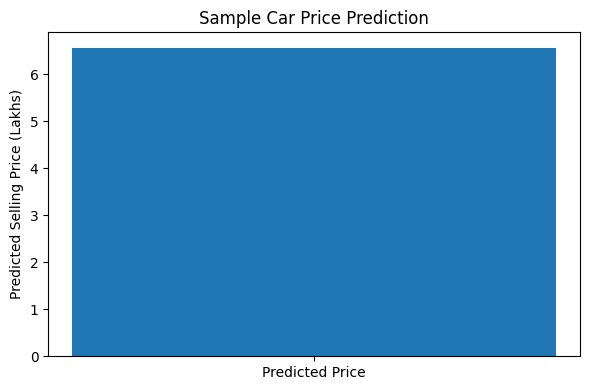

In [19]:
plt.figure(figsize=(6, 4))
plt.bar(
    ["Predicted Price"],
    [predicted_price]
)
plt.title("Sample Car Price Prediction")
plt.ylabel("Predicted Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

## 7. Conclusion

This project demonstrates how machine learning regression algorithms can be used to estimate the selling prices of used cars based on their characteristics.

Exploratory Data Analysis was performed to understand price distributions and relationships between car features. Linear Regression, Decision Tree Regressor, and Random Forest Regressor were trained and compared using MAE, RMSE, and R² score.

The best-performing model was selected based on test-set R² score. Actual-versus-predicted and residual plots were used to inspect prediction performance, and a sample car price prediction was demonstrated.

The results are based on the available dataset and should not be treated as guaranteed market prices.